In [11]:
import zipfile

zip_path = "/content/archive.zip"  # Your ZIP file path
extract_path = "/content/cricket_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("File unzipped successfully!")

File unzipped successfully!


In [12]:
import pandas as pd

In [19]:
df=pd.read_csv("/content/clean_matches.csv")

In [20]:
df.shape

(636, 17)

# **Part A: Get to know your data**

# **First look**

In [36]:
df.head(10)

,match_id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
631,632,2016,Raipur,2016-05-22,Delhi Daredevils,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,6,V Kohli,Shaheed Veer Narayan Singh International Stadium,A Nand Kishore,BNJ Oxenford
632,633,2016,Bangalore,2016-05-24,Gujarat Lions,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,4,AB de Villiers,M Chinnaswamy Stadium,AK Chaudhary,HDPK Dharmasena
633,634,2016,Delhi,2016-05-25,Sunrisers Hyderabad,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Sunrisers Hyderabad,22,0,MC Henriques,Feroz Shah Kotla,M Erasmus,C Shamshuddin
634,635,2016,Delhi,2016-05-27,Gujarat Lions,Sunrisers Hyderabad,Sunrisers Hyderabad,field,normal,0,Sunrisers Hyderabad,0,4,DA Warner,Feroz Shah Kotla,M Erasmus,CK Nandan
635,636,2016,Bangalore,2016-05-29,Sunrisers Hyderabad,Royal Challengers Bangalore,Sunrisers Hyderabad,bat,normal,0,Sunrisers Hyderabad,8,0,BCJ Cutting,M Chinnaswamy Stadium,HDPK Dharmasena,BNJ Oxenford


In [37]:
df.tail(5)

,match_id,season,city,date,team1,team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2
631,632,2016,Raipur,2016-05-22,Delhi Daredevils,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,6,V Kohli,Shaheed Veer Narayan Singh International Stadium,A Nand Kishore,BNJ Oxenford
632,633,2016,Bangalore,2016-05-24,Gujarat Lions,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,4,AB de Villiers,M Chinnaswamy Stadium,AK Chaudhary,HDPK Dharmasena
633,634,2016,Delhi,2016-05-25,Sunrisers Hyderabad,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Sunrisers Hyderabad,22,0,MC Henriques,Feroz Shah Kotla,M Erasmus,C Shamshuddin
634,635,2016,Delhi,2016-05-27,Gujarat Lions,Sunrisers Hyderabad,Sunrisers Hyderabad,field,normal,0,Sunrisers Hyderabad,0,4,DA Warner,Feroz Shah Kotla,M Erasmus,CK Nandan
635,636,2016,Bangalore,2016-05-29,Sunrisers Hyderabad,Royal Challengers Bangalore,Sunrisers Hyderabad,bat,normal,0,Sunrisers Hyderabad,8,0,BCJ Cutting,M Chinnaswamy Stadium,HDPK Dharmasena,BNJ Oxenford


# **2. Guess first — most common category**

In [40]:
print(df["city"].value_counts())

city
Mumbai            85
Bangalore         66
Kolkata           61
Delhi             60
Hyderabad         49
Chennai           48
Chandigarh        46
Jaipur            33
Pune              32
Durban            15
Centurion         12
Ahmedabad         12
Visakhapatnam     11
Rajkot            10
Dharamsala         9
Johannesburg       8
Cape Town          7
Port Elizabeth     7
Ranchi             7
Abu Dhabi          7
Cuttack            7
Raipur             6
Sharjah            6
Indore             5
Kochi              5
Kanpur             4
East London        3
Kimberley          3
Nagpur             3
Bloemfontein       2
Name: count, dtype: int64


# **3:Size and types**

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   match_id         636 non-null    int64 
 1   season           636 non-null    int64 
 2   city             629 non-null    object
 3   date             636 non-null    object
 4   team1            636 non-null    object
 5   team2            636 non-null    object
 6   toss_winner      636 non-null    object
 7   toss_decision    636 non-null    object
 8   result           636 non-null    object
 9   dl_applied       636 non-null    int64 
 10  winner           633 non-null    object
 11  win_by_runs      636 non-null    int64 
 12  win_by_wickets   636 non-null    int64 
 13  player_of_match  633 non-null    object
 14  venue            636 non-null    object
 15  umpire1          635 non-null    object
 16  umpire2          635 non-null    object
dtypes: int64(5), object(12)
memory usag

# **Quick stats**

In [43]:
df.describe(include='object')

,city,date,team1,team2,toss_winner,toss_decision,result,winner,player_of_match,venue,umpire1,umpire2
count,629,636,636,636,636,636,636,633,633,636,635,635
unique,30,450,14,14,14,2,3,14,201,35,44,45
top,Mumbai,2016-05-08,Mumbai Indians,Delhi Daredevils,Mumbai Indians,field,normal,Mumbai Indians,CH Gayle,M Chinnaswamy Stadium,HDPK Dharmasena,SJA Taufel
freq,85,2,82,84,85,363,626,92,18,66,73,54


In [47]:
print(df.sort_values("win_by_runs", ascending=False).head(5))

     match_id  season       city        date                        team1  \
43         44    2017      Delhi  2017-05-06               Mumbai Indians   
619       620    2016  Bangalore  2016-05-14  Royal Challengers Bangalore   
59         60    2008  Bangalore  2008-04-18        Kolkata Knight Riders   
556       557    2015  Bangalore  2015-05-06  Royal Challengers Bangalore   
410       411    2013  Bangalore  2013-04-23  Royal Challengers Bangalore   

                           team2                  toss_winner toss_decision  \
43              Delhi Daredevils             Delhi Daredevils         field   
619                Gujarat Lions                Gujarat Lions         field   
59   Royal Challengers Bangalore  Royal Challengers Bangalore         field   
556              Kings XI Punjab              Kings XI Punjab         field   
410                Pune Warriors                Pune Warriors         field   

     result  dl_applied                       winner  win_by_r

# **# Part B Clean it**

# **6:Missing values**

In [49]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
match_id           0
season             0
city               7
date               0
team1              0
team2              0
toss_winner        0
toss_decision      0
result             0
dl_applied         0
winner             3
win_by_runs        0
win_by_wickets     0
player_of_match    3
venue              0
umpire1            1
umpire2            1
dtype: int64


In [50]:
print("\nMissing percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))


Missing percentage:
match_id           0.00
season             0.00
city               1.10
date               0.00
team1              0.00
team2              0.00
toss_winner        0.00
toss_decision      0.00
result             0.00
dl_applied         0.00
winner             0.47
win_by_runs        0.00
win_by_wickets     0.00
player_of_match    0.47
venue              0.00
umpire1            0.16
umpire2            0.16
dtype: float64


**7.Decide and fix.**

As city should be filled with null and other column have just few enteris so we can drop them like player of the match as it may be if filed with mod he may not be in that team

In [52]:
df["city"] = df["city"].fillna(df["city"].mode()[0])

In [53]:
df = df.dropna()

In [54]:
df.shape

(632, 17)

# **8.Duplicates**

In [58]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### **9.Wrong Enteries**

In [56]:
for col in df.columns:
    if col != "match_id":
        print(f"\n{col}:")
        print(df[col].unique())


season:
[2017 2008 2009 2010 2011 2012 2013 2014 2015 2016]

city:
['Hyderabad' 'Pune' 'Rajkot' 'Indore' 'Mumbai' 'Kolkata' 'Bangalore'
 'Delhi' 'Chandigarh' 'Kanpur' 'Jaipur' 'Chennai' 'Cape Town'
 'Port Elizabeth' 'Durban' 'Centurion' 'East London' 'Johannesburg'
 'Kimberley' 'Bloemfontein' 'Ahmedabad' 'Cuttack' 'Nagpur' 'Dharamsala'
 'Kochi' 'Visakhapatnam' 'Raipur' 'Ranchi' 'Abu Dhabi' 'Sharjah']

date:
['2017-04-05' '2017-04-06' '2017-04-07' '2017-04-08' '2017-04-09'
 '2017-04-10' '2017-04-11' '2017-04-12' '2017-04-13' '2017-04-14'
 '2017-04-15' '2017-04-16' '2017-04-17' '2017-04-18' '2017-04-19'
 '2017-04-20' '2017-04-21' '2017-04-22' '2017-04-23' '2017-04-24'
 '2017-04-26' '2017-04-27' '2017-04-28' '2017-04-29' '2017-04-30'
 '2017-05-01' '2017-05-02' '2017-05-03' '2017-05-04' '2017-05-05'
 '2017-05-06' '2017-05-07' '2017-05-08' '2017-05-09' '2017-05-10'
 '2017-05-11' '2017-05-12' '2017-05-13' '2017-05-14' '2017-05-16'
 '2017-05-17' '2017-05-19' '2017-05-21' '2008-04-18' '2008-0

Wrong values: Checked win_by_runs and win_by_wickets for zero and negative values. The seven rows with zero in both columns had a tie result, so the zeros were valid and were retained. No values were changed based on this check.

In [57]:
print(df[(df["win_by_runs"] == 0) & (df["win_by_wickets"] == 0)])

     match_id  season       city        date                        team1  \
33         34    2017     Rajkot  2017-04-29                Gujarat Lions   
125       126    2009  Cape Town  2009-04-23             Rajasthan Royals   
189       190    2010    Chennai  2010-03-21              Kings XI Punjab   
387       388    2013  Hyderabad  2013-04-07  Royal Challengers Bangalore   
400       401    2013  Bangalore  2013-04-16             Delhi Daredevils   
475       476    2014  Abu Dhabi  2014-04-29             Rajasthan Royals   
535       536    2015  Ahmedabad  2015-04-21             Rajasthan Royals   

                           team2                  toss_winner toss_decision  \
33                Mumbai Indians                Gujarat Lions           bat   
125        Kolkata Knight Riders        Kolkata Knight Riders         field   
189          Chennai Super Kings          Chennai Super Kings         field   
387          Sunrisers Hyderabad  Royal Challengers Bangalore      

10.Outliers by IQR

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 632 entries, 0 to 635
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   match_id         632 non-null    int64 
 1   season           632 non-null    int64 
 2   city             632 non-null    object
 3   date             632 non-null    object
 4   team1            632 non-null    object
 5   team2            632 non-null    object
 6   toss_winner      632 non-null    object
 7   toss_decision    632 non-null    object
 8   result           632 non-null    object
 9   dl_applied       632 non-null    int64 
 10  winner           632 non-null    object
 11  win_by_runs      632 non-null    int64 
 12  win_by_wickets   632 non-null    int64 
 13  player_of_match  632 non-null    object
 14  venue            632 non-null    object
 15  umpire1          632 non-null    object
 16  umpire2          632 non-null    object
dtypes: int64(5), object(12)
memory usage: 88

In [67]:
Q1 = df["win_by_runs"].quantile(0.25)
Q3 = df["win_by_runs"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["win_by_runs"] < lower) |
    (df["win_by_runs"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of outliers:", len(outliers))

Q1: 0.0
Q3: 20.0
IQR: 20.0
Lower limit: -30.0
Upper limit: 50.0
Number of outliers: 47


In [66]:
print(outliers[["match_id", "season", "winner", "win_by_runs"]])

     match_id  season                       winner  win_by_runs
8           9    2017             Delhi Daredevils           97
14         15    2017             Delhi Daredevils           51
26         27    2017        Kolkata Knight Riders           82
32         33    2017       Rising Pune Supergiant           61
43         44    2017               Mumbai Indians          146
59         60    2008        Kolkata Knight Riders          140
68         69    2008              Kings XI Punjab           66
100       101    2008             Rajasthan Royals           65
114       115    2008             Rajasthan Royals          105
118       119    2009  Royal Challengers Bangalore           75
121       122    2009          Chennai Super Kings           92
131       132    2009               Mumbai Indians           92
143       144    2009          Chennai Super Kings           78
144       145    2009             Rajasthan Royals           78
154       155    2009              Decca

# **Part:3 Visualize**

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
df = pd.read_csv("clean_matches.csv")

runs = df[df["win_by_runs"] > 0]

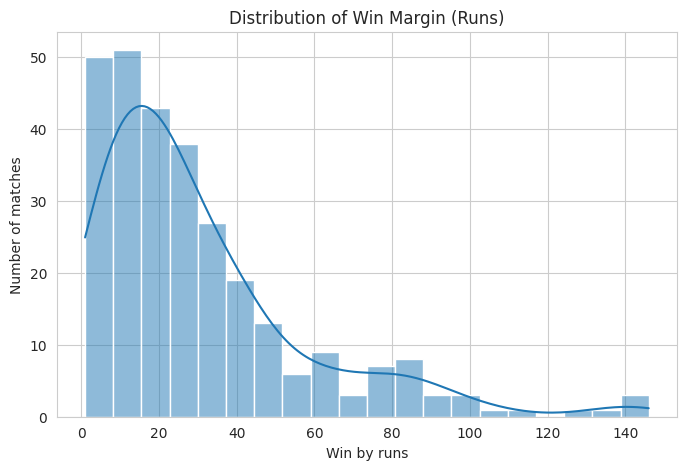

Skewness: 1.7543315989108275


In [70]:
plt.figure(figsize=(8, 5))
sns.histplot(runs["win_by_runs"], bins=20, kde=True)
plt.title("Distribution of Win Margin (Runs)")
plt.xlabel("Win by runs")
plt.ylabel("Number of matches")
plt.show()

print("Skewness:", runs["win_by_runs"].skew())


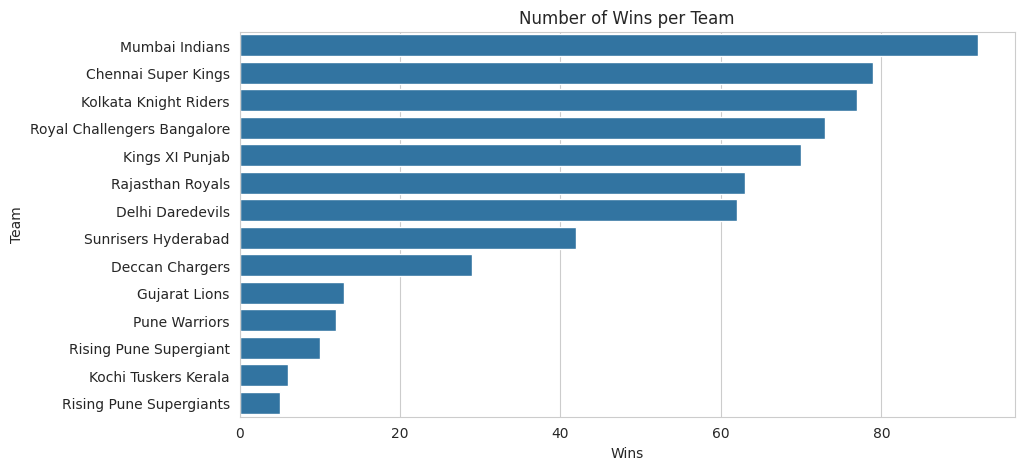

In [71]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="winner", order=df["winner"].value_counts().index)
plt.title("Number of Wins per Team")
plt.xlabel("Wins")
plt.ylabel("Team")
plt.show()

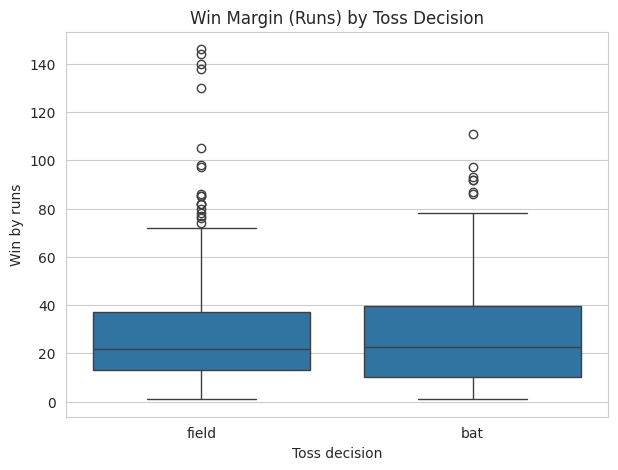

In [73]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=runs, x="toss_decision", y="win_by_runs")
plt.title("Win Margin (Runs) by Toss Decision")
plt.xlabel("Toss decision")
plt.ylabel("Win by runs")
plt.show()

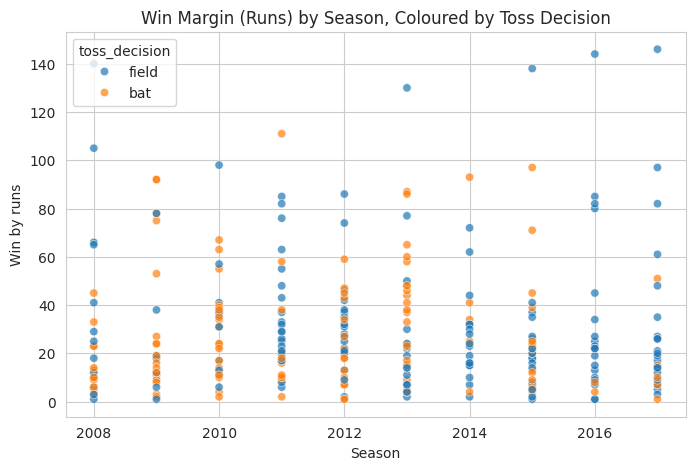

Correlation: -0.0021850212690858956


In [72]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=runs, x="season", y="win_by_runs", hue="toss_decision", alpha=0.7)
plt.title("Win Margin (Runs) by Season, Coloured by Toss Decision")
plt.xlabel("Season")
plt.ylabel("Win by runs")
plt.show()

print("Correlation:", runs["season"].corr(runs["win_by_runs"]))

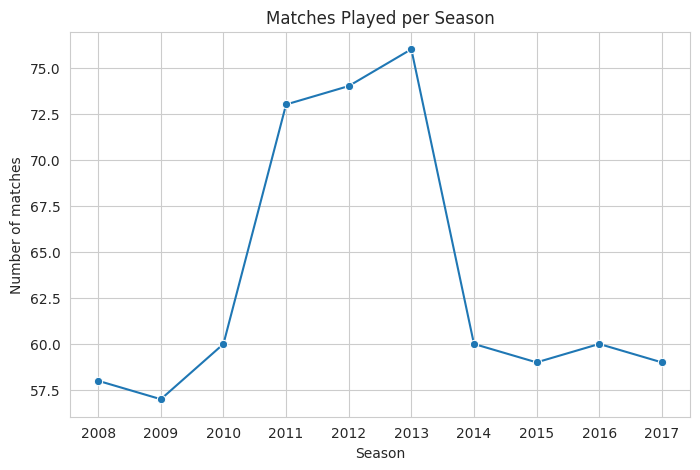

In [74]:
matches_per_season = df.groupby("season").size()

plt.figure(figsize=(8, 5))
sns.lineplot(x=matches_per_season.index, y=matches_per_season.values, marker="o")
plt.title("Matches Played per Season")
plt.xlabel("Season")
plt.ylabel("Number of matches")
plt.xticks(matches_per_season.index)
plt.show()



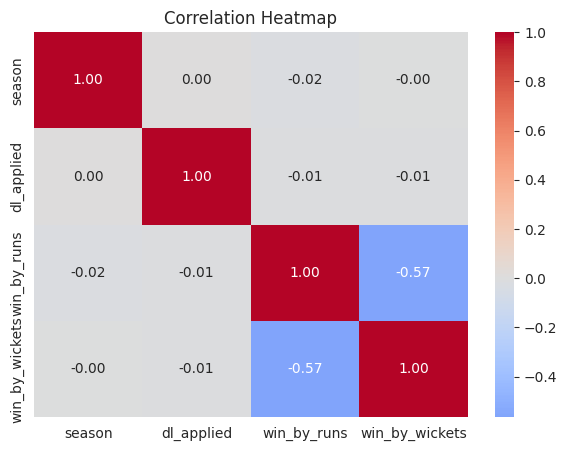

Strongest pair: ('win_by_runs', 'win_by_wickets') -> 0.57


In [76]:
num_cols = df[["season", "dl_applied", "win_by_runs", "win_by_wickets"]]
corr = num_cols.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

pairs = corr.abs().unstack().sort_values(ascending=False)
pairs = pairs[pairs < 1]
print("Strongest pair:", pairs.index[0], "->", round(pairs.iloc[0], 2))